In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('Titanic-Dataset.csv')

# Impute missing values
df = df.fillna({
    'Age': df['Age'].median(),
    'Cabin': 'Unknown',
    'Embarked': df['Embarked'].mode()[0]
})

# Feature extraction & categorical encoding
df['Deck'] = df['Cabin'].str[0]
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

df_model = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
df_model = pd.get_dummies(df_model, columns=['Embarked', 'Deck'], drop_first=True, dtype=int)

X = df_model.drop(columns=['Survived'])
y = df_model['Survived']

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Stratified split preserves the 38.4% positive survival ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize numerical columns (fit on train set only to avoid data leakage)
scaler = StandardScaler()
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [3]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

Precision: 0.8136
Recall:    0.6957
F1-Score:  0.7500
ROC-AUC:   0.8410

Confusion Matrix:
 [[99 11]
 [21 48]]


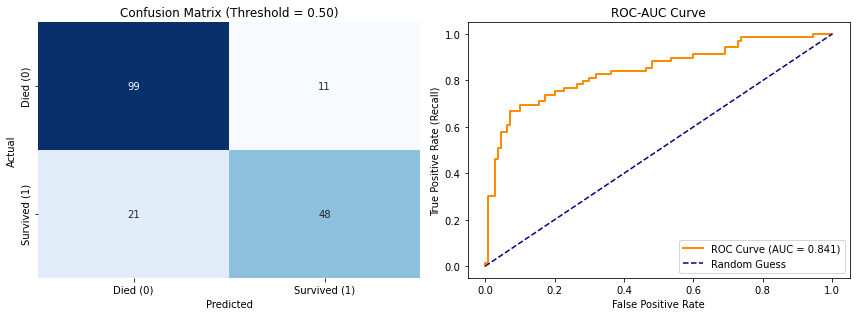

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve
)

# Predicted probabilities for class 1 and default 0.50 class predictions
y_prob = log_reg.predict_proba(X_test)[:, 1]
y_pred = log_reg.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print("\nConfusion Matrix:\n", cm)

# Plot Confusion Matrix & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Died (0)', 'Survived (1)'],
            yticklabels=['Died (0)', 'Survived (1)'])
axes[0].set_title('Confusion Matrix (Threshold = 0.50)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guess')
axes[1].set_title('ROC-AUC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

In [5]:
# Evaluate Precision, Recall, and F1 across probability thresholds from 0.20 to 0.70
thresholds = np.arange(0.20, 0.75, 0.05)
tuning_results = []

for t in thresholds:
    preds_t = (y_prob >= t).astype(int)
    tuning_results.append({
        'Threshold': round(t, 2),
        'Precision': round(precision_score(y_test, preds_t), 4),
        'Recall': round(recall_score(y_test, preds_t), 4),
        'F1_Score': round(f1_score(y_test, preds_t), 4)
    })

tuning_df = pd.DataFrame(tuning_results)
print(tuning_df.to_string(index=False))

# Example: Apply a lower threshold (e.g., 0.35) if prioritizing Recall (catching more survivors)
custom_threshold = 0.35
y_pred_tuned = (y_prob >= custom_threshold).astype(int)
print(f"\nConfusion Matrix at Threshold {custom_threshold}:\n", confusion_matrix(y_test, y_pred_tuned))

 Threshold  Precision  Recall  F1_Score
      0.20     0.6000  0.8261    0.6951
      0.25     0.6250  0.7971    0.7006
      0.30     0.6506  0.7826    0.7105
      0.35     0.6625  0.7681    0.7114
      0.40     0.7083  0.7391    0.7234
      0.45     0.7206  0.7101    0.7153
      0.50     0.8136  0.6957    0.7500
      0.55     0.8519  0.6667    0.7480
      0.60     0.8511  0.5797    0.6897
      0.65     0.8810  0.5362    0.6667
      0.70     0.8947  0.4928    0.6355

Confusion Matrix at Threshold 0.35:
 [[83 27]
 [16 53]]
